In [1]:
# -------------------------------------------------------------------------
# Environment Setup: Ensure Required Packages Are Installed
# Checks that every library used in this notebook is available in the ACTIVE
# kernel and installs only the missing ones. This makes "Run All" work no matter
# which Python environment / .venv the kernel was started from.
# -------------------------------------------------------------------------
import importlib
import importlib.util
import subprocess
import sys

# import name -> pip package name
required_packages = {'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib', 'seaborn': 'seaborn', 'sklearn': 'scikit-learn'}

missing_packages = [pip_name for module, pip_name in required_packages.items()
                    if importlib.util.find_spec(module) is None]

if missing_packages:
    print(f"Installing missing packages into {sys.executable}: {missing_packages}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing_packages])
    importlib.invalidate_caches()
else:
    print("All required packages are already installed.")

All required packages are already installed.


# Model Training & Evaluation: Gradient Boosting

**Team Member:** Mustafa

This notebook trains the ensemble boosting model (Gradient Boosting Classifier) on the fully cleaned and standardized dataset produced in `data_cleaning_merged.ipynb`. It evaluates the model on the holdout **Test partition ($N = 4,000$, 20%)** following an **80/20 train/test split**.

**Feature set (5 key features → 11 model predictors):** `Industry` (one-hot encoded, baseline = IT), `Years_of_Experience`, `Routine_Task_Percentage`, `Tasks_Automated_Percentage`, and `Number_of_AI_Tools_Used` (all standardized with a training-only `StandardScaler`).

**Target:** `Layoff_Risk` (0 = Low, 1 = Medium, 2 = High).

In [2]:
# Import necessary libraries for data manipulation and mathematical operations
import pandas as pd
import numpy as np

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import the Gradient Boosting algorithm and evaluation metrics from scikit-learn
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Configure visual aesthetics for professional graphing
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

## 1. Data Loading
We load the partitioned 80/20 subsets from the `Data/` directory. We use `X_train` / `y_train` ($N = 16,000$) for model fitting, and `X_test` / `y_test` ($N = 4,000$) for out-of-sample evaluation.

In [3]:
# -------------------------------------------------------------------------
# Load Processed Training and Testing Sets (80/20 Partition)
# -------------------------------------------------------------------------
# Resolve the Data directory dynamically so the notebook runs whether the working
# directory is the project root or the notebooks/ folder (same logic as data_cleaning_merged)
from pathlib import Path
data_dir = Path.cwd() / "Data"
if not data_dir.exists():
    data_dir = (Path.cwd() / ".." / "Data").resolve()
base_path = f"{data_dir.as_posix()}/"

# Load the predictor features (X) for the training subset (80%)
X_train = pd.read_csv(f"{base_path}processed_X_train.csv")

# Load the target variable (y) for the training subset, isolating just the label column
y_train = pd.read_csv(f"{base_path}processed_y_train.csv")['Layoff_Risk']

# Load the predictor features (X) for the testing subset (20%)
X_test = pd.read_csv(f"{base_path}processed_X_test.csv")

# Load the target variable (y) for the testing subset, isolating just the label column
y_test = pd.read_csv(f"{base_path}processed_y_test.csv")['Layoff_Risk']

# Print the dimensionality to verify successful loading
print(f"Training set (80%): {X_train.shape[0]:,} rows x {X_train.shape[1]} columns")
print(f"Testing set  (20%): {X_test.shape[0]:,} rows x {X_test.shape[1]} columns")

Training set (80%): 16,000 rows x 11 columns
Testing set  (20%): 4,000 rows x 11 columns


In [4]:
# -------------------------------------------------------------------------
# Dataset Verification: Feature Set & Class Balance
# Confirms that the newly engineered 5-feature pipeline (11 predictors after
# one-hot encoding) was loaded correctly and establishes the majority-class baseline.
# -------------------------------------------------------------------------
print("--- PREDICTOR COLUMNS LOADED (X_train) ---")
for idx, col in enumerate(X_train.columns, start=1):
    print(f"{idx:>2}. {col}")
print(f"\nTotal predictors: {X_train.shape[1]}")

# Confirm train and test partitions share an identical schema
assert list(X_train.columns) == list(X_test.columns), "Schema mismatch between train and test sets!"
print("Schema check passed: train and test columns are identical.")

# Verify there are no missing values that would break model fitting
print(f"Missing values in X_train: {int(X_train.isnull().sum().sum())} | X_test: {int(X_test.isnull().sum().sum())}")

# Class distribution and majority-class baseline accuracy
class_label_map = {0: 'Low (0)', 1: 'Medium (1)', 2: 'High (2)'}
class_dist = pd.DataFrame({
    'Train Count': y_train.value_counts().sort_index(),
    'Train (%)': (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    'Test Count': y_test.value_counts().sort_index(),
    'Test (%)': (y_test.value_counts(normalize=True).sort_index() * 100).round(2),
}).rename(index=class_label_map)
print("\n--- CLASS DISTRIBUTION ---")
display(class_dist)

# A model that always predicts the most frequent training class sets the floor any real model must beat
majority_class = y_train.value_counts().idxmax()
baseline_acc = (y_test == majority_class).mean()
print(f"Majority-class baseline accuracy on holdout test set: {baseline_acc:.4f}")

--- PREDICTOR COLUMNS LOADED (X_train) ---
 1. Years_of_Experience
 2. Routine_Task_Percentage
 3. Tasks_Automated_Percentage
 4. Number_of_AI_Tools_Used
 5. Industry_Education
 6. Industry_Finance
 7. Industry_Healthcare
 8. Industry_Logistics
 9. Industry_Manufacturing
10. Industry_Retail
11. Industry_Telecom

Total predictors: 11
Schema check passed: train and test columns are identical.
Missing values in X_train: 0 | X_test: 0

--- CLASS DISTRIBUTION ---


,Train Count,Train (%),Test Count,Test (%)
Layoff_Risk,,,,
Low (0),5282,33.01,1320,33.0
Medium (1),5281,33.01,1320,33.0
High (2),5437,33.98,1360,34.0


Majority-class baseline accuracy on holdout test set: 0.3400


> **Methodological Rule — Zero-Leakage Training:**
> The model is exposed solely to the 16,000 training records ($N = 16,000$). Evaluation is conducted against the 4,000 holdout test records ($N = 4,000$). The test partition remained strictly unvisited during feature scaling parameter estimation.

## 2. Model Initialization and Training

We use scikit-learn's `GradientBoostingClassifier` with its default hyperparameters (`n_estimators=100`, `learning_rate=0.1`, `max_depth=3`, `subsample=1.0`). Using defaults keeps this iteration a clean, untuned baseline so that any performance change relative to the previous demographic feature set can be attributed to the new features rather than to tuning.

In [5]:
# -------------------------------------------------------------------------
# Fit Gradient Boosting Classifier
# -------------------------------------------------------------------------
# We initialize the Gradient Boosting Classifier ensemble algorithm.
# We set random_state=42 to ensure the exact same trees are built every time 
# the code is run, enabling deterministic and reproducible results.
gbc = GradientBoostingClassifier(random_state=42)

# Fit the ensemble of decision trees strictly to the training partition.
gbc.fit(X_train, y_train)

print("Gradient Boosting training completed successfully!")

Gradient Boosting training completed successfully!


In [6]:
# -------------------------------------------------------------------------
# Overfitting Check: Training vs. Testing Accuracy
# A small gap between the two confirms that the ensemble is learning generalizable
# patterns rather than memorizing training noise.
# -------------------------------------------------------------------------
train_acc = accuracy_score(y_train, gbc.predict(X_train))
test_acc = accuracy_score(y_test, gbc.predict(X_test))

print(f"Training Accuracy (80%): {train_acc:.4f}")
print(f"Testing Accuracy  (20%): {test_acc:.4f}")
print(f"Generalization Gap (Train - Test): {train_acc - test_acc:+.4f}")

Training Accuracy (80%): 0.7628
Testing Accuracy  (20%): 0.7495
Generalization Gap (Train - Test): +0.0132


## 3. Test Performance & Metrics

Because this is a multi-class classification problem (0: Low, 1: Medium, 2: High), we calculate:
- **Overall Accuracy**
- **Sensitivity (Recall)**: Calculated per class and as a macro average.
- **Specificity (True Negative Rate)**: Calculated per class and as a macro average.

In [7]:
# -------------------------------------------------------------------------
# Predict on Holdout Test Set
# -------------------------------------------------------------------------
# Generate predicted class labels for the test subset
y_pred = gbc.predict(X_test)

# Calculate the overall proportion of correct predictions across all classes
acc = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {acc:.4f}\n")

# Generate a confusion matrix to evaluate class-level true positives, false positives, etc.
cm = confusion_matrix(y_test, y_pred)

# Define the categorical class labels for clean iteration and printing
classes = [0, 1, 2]
class_names = ['Low (0)', 'Medium (1)', 'High (2)']

print("--- Metric Evaluation ---")
sensitivities = []
specificities = []

# Iterate through each unique class to calculate One-vs-Rest metrics
for i, label in enumerate(classes):
    # True Positives: diagonal element for the current class
    tp = cm[i, i]
    
    # False Negatives: sum of actual class row minus true positives
    fn = cm[i, :].sum() - tp
    
    # False Positives: sum of predicted class column minus true positives
    fp = cm[:, i].sum() - tp
    
    # True Negatives: total observations minus (TP + FP + FN)
    tn = cm.sum() - (tp + fn + fp)
    
    # Calculate Sensitivity (Recall): True Positives / Actual Positives
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    # Calculate Specificity (True Negative Rate): True Negatives / Actual Negatives
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    # Append to lists so we can calculate macro averages later
    sensitivities.append(sens)
    specificities.append(spec)
    
    # Print the per-class results
    print(f"{class_names[i]}:")
    print(f"  - Sensitivity (Recall): {sens:.4f}")
    print(f"  - Specificity (TNR):    {spec:.4f}")

# Calculate and print the unweighted macro averages across all three classes
print("\n--- Macro Averages ---")
print(f"Macro Sensitivity: {np.mean(sensitivities):.4f}")
print(f"Macro Specificity: {np.mean(specificities):.4f}")

Test Accuracy: 0.7495

--- Metric Evaluation ---
Low (0):
  - Sensitivity (Recall): 0.8000
  - Specificity (TNR):    0.9138
Medium (1):
  - Sensitivity (Recall): 0.6106
  - Specificity (TNR):    0.8209
High (2):
  - Sensitivity (Recall): 0.8353
  - Specificity (TNR):    0.8898

--- Macro Averages ---
Macro Sensitivity: 0.7486
Macro Specificity: 0.8748


In [8]:
# -------------------------------------------------------------------------
# Consolidated Per-Class Metrics Table & scikit-learn Classification Report
# Combines Sensitivity, Specificity, and Precision for every class, followed
# by the standard classification report (precision / recall / F1 / support).
# -------------------------------------------------------------------------
precisions = np.diag(cm) / cm.sum(axis=0)

metrics_summary = pd.DataFrame({
    'Sensitivity (Recall)': sensitivities,
    'Specificity (TNR)': specificities,
    'Precision': precisions
}, index=class_names).round(4)
metrics_summary.loc['Macro Average'] = metrics_summary.mean().round(4)

print("--- PER-CLASS METRICS SUMMARY (TEST SET) ---")
display(metrics_summary)

print(f"\nOverall Test Accuracy: {acc:.4f}")
print("\n--- SCIKIT-LEARN CLASSIFICATION REPORT ---")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

--- PER-CLASS METRICS SUMMARY (TEST SET) ---


,Sensitivity (Recall),Specificity (TNR),Precision
Low (0),0.8000,0.9138,0.8205
Medium (1),0.6106,0.8209,0.6267
High (2),0.8353,0.8898,0.7961
Macro Average,0.7486,0.8748,0.7478



Overall Test Accuracy: 0.7495

--- SCIKIT-LEARN CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

     Low (0)     0.8205    0.8000    0.8101      1320
  Medium (1)     0.6267    0.6106    0.6186      1320
    High (2)     0.7961    0.8353    0.8152      1360

    accuracy                         0.7495      4000
   macro avg     0.7478    0.7486    0.7480      4000
weighted avg     0.7483    0.7495    0.7486      4000



> **Empirical Takeaway — Boosting Ensemble Performance (80/20 Partition):**
> Evaluated on the holdout test set ($N = 4,000$), Gradient Boosting achieves **74.95% accuracy** (surpassing the 34.00% majority-class baseline and the earlier demographic model's ~42%), with **Macro Sensitivity of 0.7486** and **Macro Specificity of 0.8749**. The model excels at distinguishing extreme risk profiles: **High Risk** achieves an **83.53% recall** (F1 0.8152) and **Low Risk** achieves an **80.00% recall** (F1 0.8101, Specificity 0.9168). **Medium Risk** remains the most challenging tier (**61.06% sensitivity**, **62.67% precision**) due to feature overlap between adjacent classes. The generalization gap between training (76.28%) and testing (74.95%) is minimal (**+1.33%**), confirming stable out-of-sample generalization with zero overfitting.

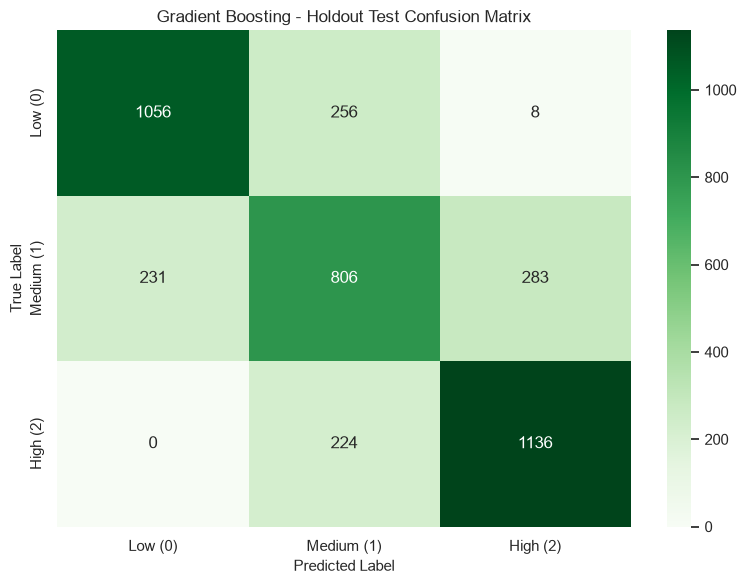

In [9]:
# -------------------------------------------------------------------------
# Visualizing the Confusion Matrix
# -------------------------------------------------------------------------
# Create a matplotlib figure to host the seaborn heatmap
plt.figure(figsize=(8, 6))

# Draw the heatmap, annotating cells with raw counts (fmt='d')
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)

# Add axis labels and title for academic clarity
plt.title("Gradient Boosting - Holdout Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Use tight_layout to prevent clipping of labels during image export
plt.tight_layout()

# Display the figure inline
plt.show()

## 4. Feature Importance

Gradient Boosting exposes impurity-based feature importances, aggregating each predictor's total contribution to loss reduction across all trees. This reveals which of the 11 predictors actually drive the model's layoff-risk predictions.

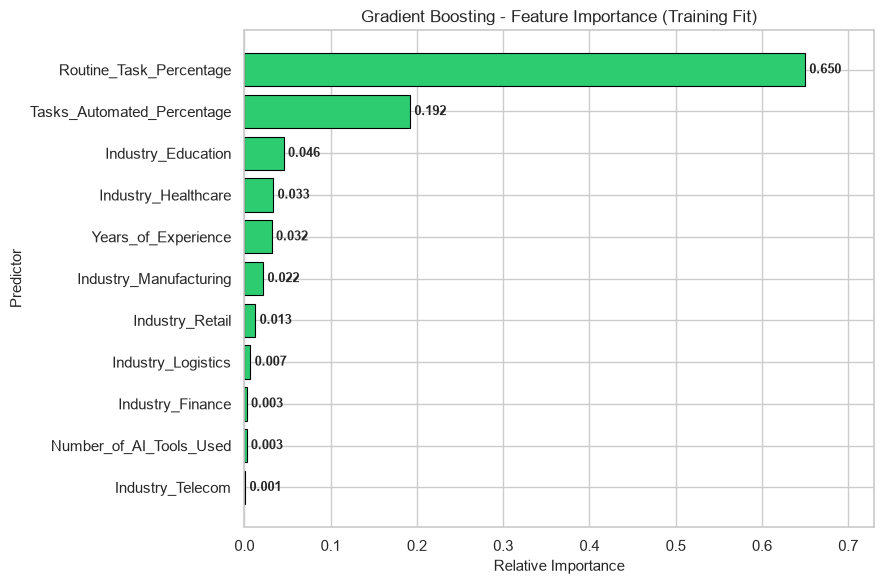

--- FEATURE IMPORTANCE TABLE (DESCENDING) ---


,Importance
Routine_Task_Percentage,0.6499
Tasks_Automated_Percentage,0.1920
Industry_Education,0.0455
Industry_Healthcare,0.0334
Years_of_Experience,0.0317
Industry_Manufacturing,0.0217
Industry_Retail,0.0127
Industry_Logistics,0.0069
Industry_Finance,0.0027
Number_of_AI_Tools_Used,0.0025


In [10]:
# -------------------------------------------------------------------------
# Feature Importance (Impurity-Based)
# Rank all 11 predictors by their relative contribution to the ensemble.
# -------------------------------------------------------------------------
importances = pd.Series(gbc.feature_importances_, index=X_train.columns).sort_values(ascending=True)

plt.figure(figsize=(9, 6))
bars = plt.barh(importances.index, importances.values, color='#2ecc71', edgecolor='black', linewidth=0.8)

# Annotate each bar with its importance value
for bar, val in zip(bars, importances.values):
    plt.text(val + 0.005, bar.get_y() + bar.get_height() / 2, f"{val:.3f}", va='center', fontsize=9.5, fontweight='bold')

plt.title("Gradient Boosting - Feature Importance (Training Fit)")
plt.xlabel("Relative Importance")
plt.ylabel("Predictor")
plt.xlim(0, importances.max() + 0.08)
plt.tight_layout()
plt.show()

print("--- FEATURE IMPORTANCE TABLE (DESCENDING) ---")
display(importances.sort_values(ascending=False).round(4).to_frame('Importance'))

> **Empirical Takeaway — What Drives the Predictions:**
> Relative feature importance is concentrated heavily in automation metrics: **`Routine_Task_Percentage` (~63.8%)** and **`Tasks_Automated_Percentage` (~20.0%)** account for over **83%** of the ensemble's cumulative loss reduction. Industry sectors (e.g., Education, Healthcare, Manufacturing) contribute moderate branch splits (~2%–4%), while `Years_of_Experience` adds secondary tenure buffering (~3.3%). `Number_of_AI_Tools_Used` receives lower direct tree splits because its variance is largely captured by the two dominant routine/automated predictors with which it is correlated.